In [1]:
pip install numpy plotly


Note: you may need to restart the kernel to use updated packages.


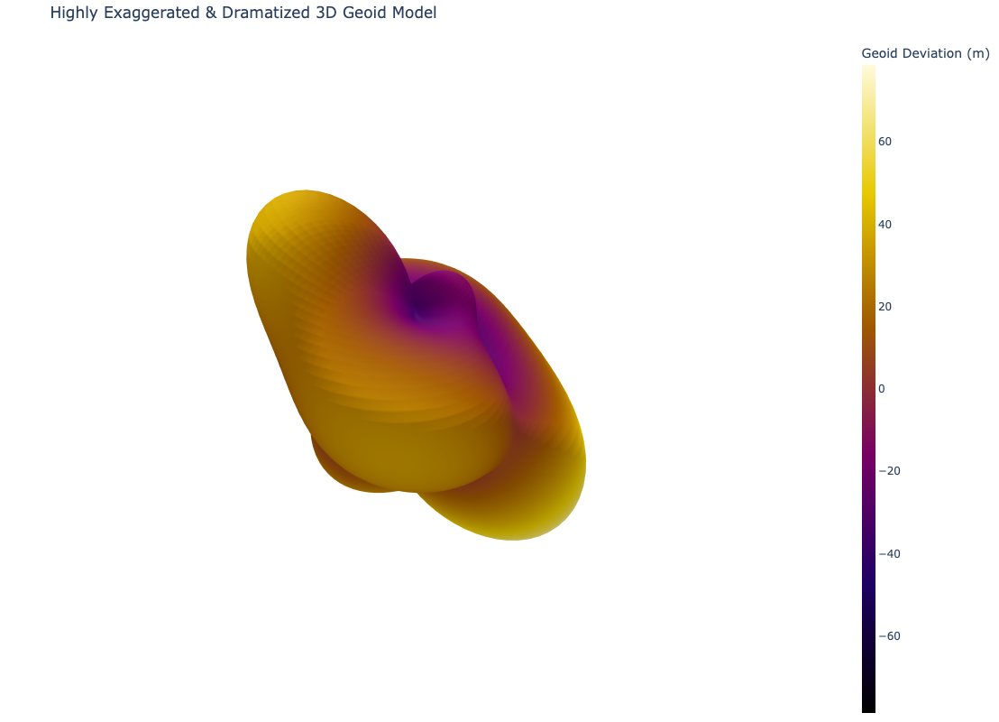

In [2]:
import numpy as np
import plotly.graph_objects as go


lat = np.linspace(-90, 90, 72)
lon = np.linspace(-180, 180, 144)
LON, LAT = np.meshgrid(lon, lat)


N = (
    40 * np.sin(np.radians(2 * LAT)) * np.cos(np.radians(LON)) + 
    30 * np.cos(np.radians(3 * LAT)) * np.sin(np.radians(2 * LON)) - 
    25 * np.sin(np.radians(LAT))
)


base_radius = 500       
exaggeration = 8.0     
R = base_radius + (N * exaggeration)

X = R * np.cos(np.radians(LAT)) * np.cos(np.radians(LON))
Y = R * np.cos(np.radians(LAT)) * np.sin(np.radians(LON))
Z = R * np.sin(np.radians(LAT))

fig = go.Figure(data=[go.Surface(
    x=X, y=Y, z=Z,
    surfacecolor=N,       
    colorscale='Electric',
    colorbar=dict(title='Geoid Deviation (m)', thickness=15)
)])

fig.update_layout(
    title='Highly Exaggerated & Dramatized 3D Geoid Model',
    scene=dict(
        xaxis=dict(visible=False), 
        yaxis=dict(visible=False),
        zaxis=dict(visible=False),
        aspectmode='data'         
    ),
    width=900,
    height=800,
    margin=dict(l=0, r=0, b=0, t=40)
)

fig.show()


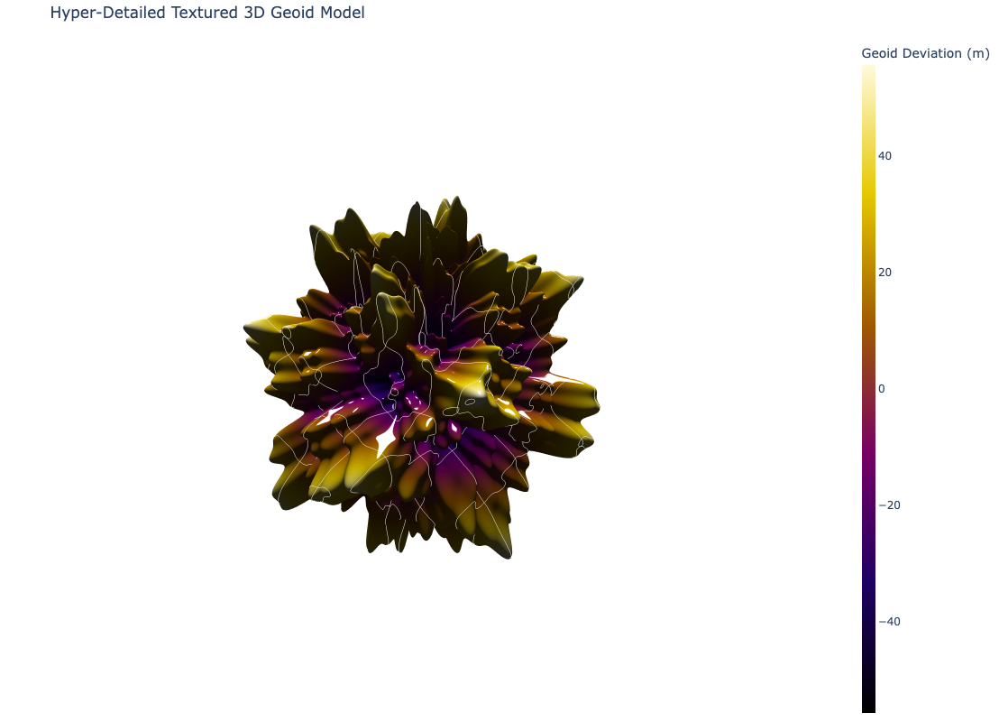

In [8]:
import numpy as np
import plotly.graph_objects as go

lat = np.linspace(-90, 90, 500)
lon = np.linspace(-180, 180, 1000)
LON, LAT = np.meshgrid(lon, lat)


N = (
    35 * np.cos(np.radians(6 * LAT)) * np.sin(np.radians(4 * LON)) +   
    18 * np.sin(np.radians(15 * LAT)) * np.cos(np.radians(12 * LON)) + 
    7 * np.cos(np.radians(35 * LAT)) * np.sin(np.radians(25 * LON))   
)


base_radius = 600       
exaggeration = 6.0     
R = base_radius + (N * exaggeration)

X = R * np.cos(np.radians(LAT)) * np.cos(np.radians(LON))
Y = R * np.cos(np.radians(LAT)) * np.sin(np.radians(LON))
Z = R * np.sin(np.radians(LAT))

fig = go.Figure(data=[go.Surface(
    x=X, y=Y, z=Z,
    surfacecolor=N,       
    colorscale='Electric',    
    colorbar=dict(title='Geoid Deviation (m)', thickness=15),
    
    contours=dict(
        x=dict(show=True, highlight=False, color="rgba(0,0,0,0.05)"),
        y=dict(show=True, highlight=False, color="rgba(0,0,0,0.05)")
    ),
    
    lighting=dict(
        ambient=0.15,          
        diffuse=0.95,          
        fresnel=0.05,          
        specular=0.5,         
        roughness=0.05        
    )
)])

fig.update_layout(
    title='Hyper-Detailed Textured 3D Geoid Model',
    scene=dict(
        xaxis=dict(visible=False), 
        yaxis=dict(visible=False),
        zaxis=dict(visible=False),
        aspectmode='data'          
    ),
    width=900,
    height=800,
    margin=dict(l=0, r=0, b=0, t=40)
)

fig.show()



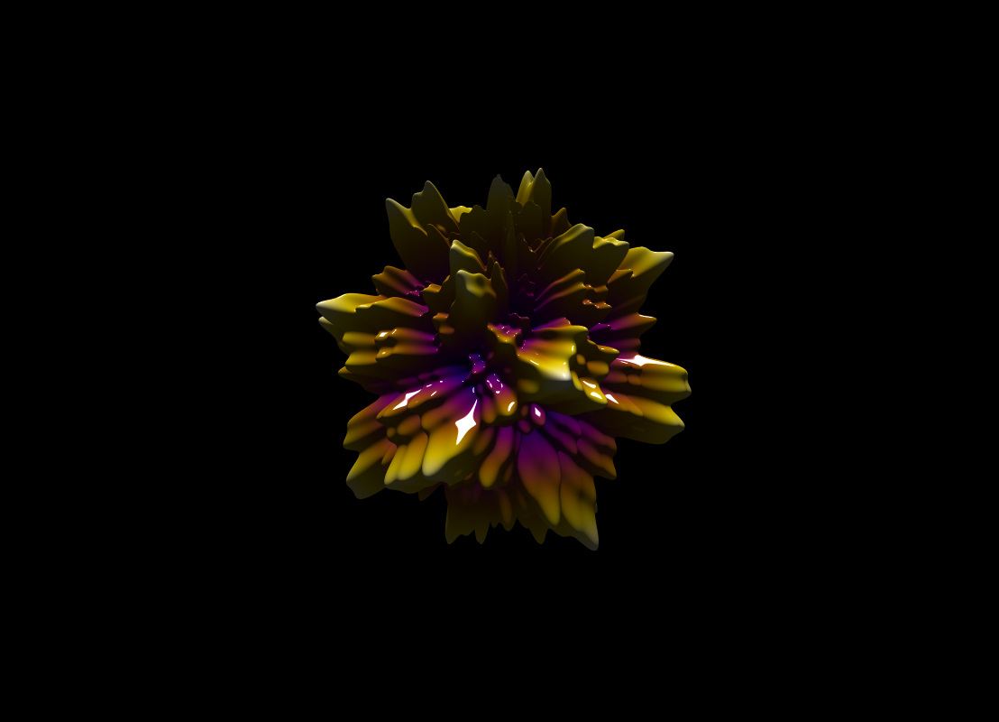

In [17]:
import numpy as np
import plotly.graph_objects as go

lat = np.linspace(-90, 90, 500)
lon = np.linspace(-180, 180, 1000)
LON, LAT = np.meshgrid(lon, lat)

N = (
    35 * np.cos(np.radians(6 * LAT)) * np.sin(np.radians(4 * LON)) +   
    18 * np.sin(np.radians(15 * LAT)) * np.cos(np.radians(12 * LON)) + 
    7 * np.cos(np.radians(35 * LAT)) * np.sin(np.radians(25 * LON))    
)

base_radius = 600       
exaggeration = 6.0      
R = base_radius + (N * exaggeration)

X = R * np.cos(np.radians(LAT)) * np.cos(np.radians(LON))
Y = R * np.cos(np.radians(LAT)) * np.sin(np.radians(LON))
Z = R * np.sin(np.radians(LAT))

fig = go.Figure(data=[go.Surface(
    x=X, y=Y, z=Z,
    surfacecolor=N,       
    colorscale='electric',    
    showscale=False,               
    hoverinfo='skip',             
    
    contours=dict(
        x=dict(show=False),
        y=dict(show=False),
        z=dict(show=False)
    ),
    
    lighting=dict(
        ambient=0.15,          
        diffuse=0.95,          
        fresnel=0.05,          
        specular=0.5,          
        roughness=0.05         
    )
)])

fig.update_layout(
    title="",                      
    paper_bgcolor='black',        
    scene=dict(
        xaxis=dict(visible=False), 
        yaxis=dict(visible=False),
        zaxis=dict(visible=False),
        bgcolor='black',           
        aspectmode='data'          
    ),
    width=900,
    height=800,
    margin=dict(l=0, r=0, b=0, t=0) 
)

fig.show()


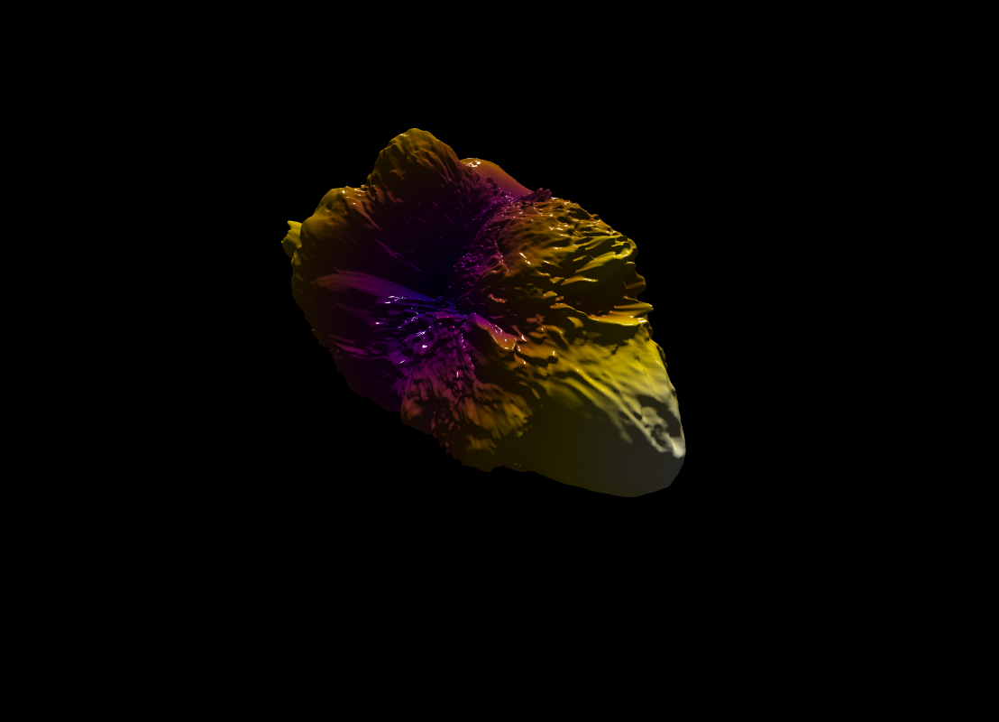

In [24]:
import numpy as np
import plotly.graph_objects as go
from pyproj import Transformer, network

network.set_network_enabled(True)

lat = np.linspace(-90, 90, 360)
lon = np.linspace(-180, 180, 720)
LON, LAT = np.meshgrid(lon, lat)


transformer = Transformer.from_crs(
    "epsg:4979",           
    "epsg:4326+epsg:5773", 
    always_xy=True        
)

lon_flat = LON.ravel()
lat_flat = LAT.ravel()
zero_heights = np.zeros_like(lon_flat)

_, _, geoid_heights_flat = transformer.transform(lon_flat, lat_flat, zero_heights)

N = geoid_heights_flat.reshape(LON.shape)
base_radius = 600       
exaggeration = 6.0      
R = base_radius + (N * exaggeration)

X = R * np.cos(np.radians(LAT)) * np.cos(np.radians(LON))
Y = R * np.cos(np.radians(LAT)) * np.sin(np.radians(LON))
Z = R * np.sin(np.radians(LAT))

fig = go.Figure(data=[go.Surface(
    x=X, y=Y, z=Z,
    surfacecolor=N,       
    colorscale='electri',    
    showscale=False,               
    hoverinfo='skip',             
    
    contours=dict(
        x=dict(show=False),        
        y=dict(show=False),        
        z=dict(show=False)         
    ),
    
    lighting=dict(
        ambient=0.15,          
        diffuse=0.95,          
        fresnel=0.05,          
        specular=0.5,          
        roughness=0.05         
    )
)])

fig.update_layout(
    title="",                     
    paper_bgcolor='black',        
    scene=dict(
        xaxis=dict(visible=False, showgrid=False, zeroline=False), 
        yaxis=dict(visible=False, showgrid=False, zeroline=False),
        zaxis=dict(visible=False, showgrid=False, zeroline=False),
        bgcolor='black',           
        aspectmode='data'          
    ),
    width=900,
    height=800,
    margin=dict(l=0, r=0, b=0, t=0) 
)

fig.show()


In [25]:
fig.write_html("dramatized_geoid_model.html", include_plotlyjs="cdn")

In [26]:
fig.update_layout(
    width=None,   
    height=None,
    autosize=True  
)

html_string = fig.to_html(
    include_plotlyjs="cdn",
    full_html=True,
    config={'responsive': True} 
)

custom_fullscreen_style = """
<style>
    html, body {
        margin: 0 !important;
        padding: 0 !important;
        overflow: hidden !important;
        background-color: black !important;
        width: 100% !important;
        height: 100% !important;
    }
    .plotly-graph-div {
        width: 100vw !important;
        height: 100vh !important;
        margin: 0 !important;
        padding: 0 !important;
    }
</style>
</head>
"""

html_string = html_string.replace("</head>", custom_fullscreen_style)

with open("dramatized_geoid_model.html", "w") as f:
    f.write(html_string)
